In [3]:
%pip install sqlalchemy psycopg2-binary

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text
from urllib.parse import quote_plus

DB_USER     = "postgres"
DB_PASSWORD = quote_plus("091973")   # <- your pgAdmin password
DB_HOST     = "localhost"
DB_PORT     = "5432"
DB_NAME     = "appleindiaDB"            # <- your database name in pgAdmin

engine = create_engine(
    f"postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}"
)

with engine.connect() as conn:
    print(conn.execute(text("SELECT version()")).scalar())

PostgreSQL 18.6 on x86_64-windows, compiled by msvc-19.44.35229, 64-bit


In [26]:
query = """
SELECT invoice, invoice_date, customer_id, customer_segment,
       gender, age_group, city, state, region, city_tier,
       category, channel, is_gift, total_amount
FROM analytics.sales
WHERE transaction_type = 'Sale'
"""
sales = pd.read_sql(query, engine, parse_dates=["invoice_date"])
print(sales.shape)
sales.head()

(656396, 14)


,invoice,invoice_date,customer_id,customer_segment,gender,age_group,city,state,region,city_tier,category,channel,is_gift,total_amount
0,1003019,2024-10-29 20:39:00,CUST-201625,Individual,Male,25-34,Mumbai,Maharashtra,West,1,Mac,Apple Retail Store,No,114900.0
1,1003020,2024-10-29 20:40:00,CUST-280192,Individual,Male,25-34,Pune,Maharashtra,West,1,iPhone,Amazon,No,83520.0
2,1003020,2024-10-29 20:40:00,CUST-280192,Individual,Male,25-34,Pune,Maharashtra,West,1,Accessories,Amazon,No,1420.0
3,1003021,2024-10-29 20:40:00,CUST-195816,Individual,Female,25-34,Bengaluru,Karnataka,South,1,iPhone,Apple Store Online,Yes,184900.0
4,1003022,2024-10-29 20:40:00,CUST-185445,Individual,Female,35-44,Jodhpur,Rajasthan,North,3,iPhone,Amazon,No,138790.0


In [27]:
sales.info()
print("Date range:", sales["invoice_date"].min(), "to", sales["invoice_date"].max())
print("Orders:", sales["invoice"].nunique())
print("Customers:", sales["customer_id"].nunique())
sales["customer_segment"].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 656396 entries, 0 to 656395
Data columns (total 14 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   invoice           656396 non-null  object        
 1   invoice_date      656396 non-null  datetime64[ns]
 2   customer_id       579363 non-null  object        
 3   customer_segment  656396 non-null  object        
 4   gender            562742 non-null  object        
 5   age_group         562742 non-null  object        
 6   city              656396 non-null  object        
 7   state             656396 non-null  object        
 8   region            656396 non-null  object        
 9   city_tier         656396 non-null  int64         
 10  category          656396 non-null  object        
 11  channel           656396 non-null  object        
 12  is_gift           656396 non-null  object        
 13  total_amount      656396 non-null  float64       
dtypes: d

customer_segment
Individual    495630
Guest          77033
Student        67112
Corporate      16621
Name: count, dtype: int64

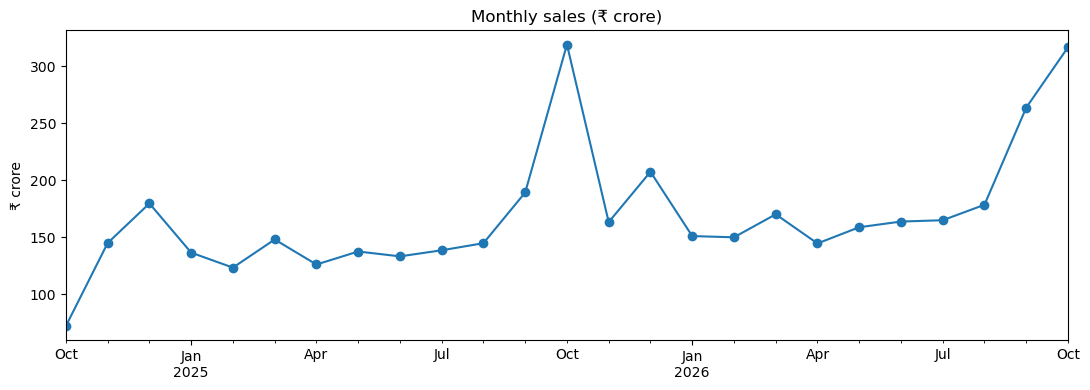

In [28]:
monthly = (sales.set_index("invoice_date")
                .resample("MS")["total_amount"].sum() / 1e7)

ax = monthly.plot(figsize=(11, 4), marker="o", title="Monthly sales (₹ crore)")
ax.set_xlabel("")
ax.set_ylabel("₹ crore")
plt.tight_layout()
plt.show()

count    238371.0
mean        122.0
std         127.0
min           0.0
50%          78.0
75%         177.0
90%         303.0
max         726.0
Name: days_since_previous, dtype: float64


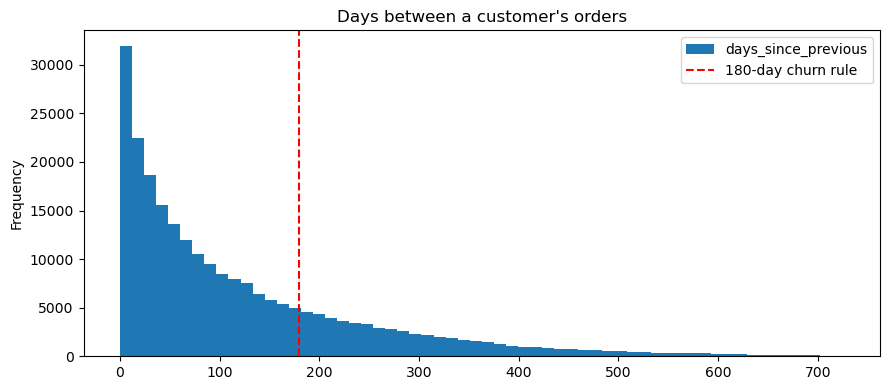

In [29]:
retail = sales[sales["customer_id"].str.startswith("CUST-", na=False)].copy()

orders = (retail[["customer_id", "invoice", "invoice_date"]]
            .drop_duplicates("invoice")
            .sort_values(["customer_id", "invoice_date"]))
orders["days_since_previous"] = (orders.groupby("customer_id")["invoice_date"]
                                       .diff().dt.days)

gaps = orders["days_since_previous"].dropna()
print(gaps.describe(percentiles=[0.5, 0.75, 0.9]).round(0))

ax = gaps.plot(kind="hist", bins=60, figsize=(9, 4),
               title="Days between a customer's orders")
ax.axvline(180, color="red", linestyle="--", label="180-day churn rule")
ax.legend()
plt.tight_layout()
plt.show()

In [30]:
order_gaps = (orders.dropna(subset=["days_since_previous"])
                    [["customer_id", "invoice", "invoice_date", "days_since_previous"]])

order_gaps.to_sql("order_gaps", engine, schema="analytics",
                  if_exists="replace", index=False, chunksize=10_000, method="multi")
print(len(order_gaps))

238371


In [31]:
# RFM SEGMENTATION
SNAPSHOT = pd.Timestamp("2026-10-27")   # the day after the data ends

rfm = (retail.groupby("customer_id")
             .agg(first_purchase=("invoice_date", "min"),
                  last_purchase =("invoice_date", "max"),
                  frequency     =("invoice", "nunique"),
                  monetary      =("total_amount", "sum"))
             .reset_index())

rfm["recency_days"] = (SNAPSHOT - rfm["last_purchase"].dt.normalize()).dt.days

print(rfm.shape)
rfm[["recency_days", "frequency", "monetary"]].describe().round(0)

(122204, 6)


,recency_days,frequency,monetary
count,122204.0,122204.0,122204.0
mean,222.0,3.0,214353.0
std,200.0,3.0,250345.0
min,1.0,1.0,1000.0
25%,41.0,1.0,64950.0
50%,164.0,2.0,144900.0
75%,368.0,4.0,274585.0
max,730.0,83.0,7077220.0


In [32]:
# SCORING EACH CUSTOMER FROM 1 TO 5
rfm["r_score"] = pd.qcut(rfm["recency_days"].rank(method="first", ascending=False),
                         5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["f_score"] = pd.qcut(rfm["frequency"].rank(method="first"),
                         5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["m_score"] = pd.qcut(rfm["monetary"].rank(method="first"),
                         5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm["rfm_score"] = (rfm["r_score"].astype(str)
                    + rfm["f_score"].astype(str)
                    + rfm["m_score"].astype(str))

rfm[["customer_id", "recency_days", "frequency", "monetary",
     "r_score", "f_score", "m_score", "rfm_score"]].head(10)

,customer_id,recency_days,frequency,monetary,r_score,f_score,m_score,rfm_score
0,CUST-100003,340,3,482240.0,2,4,5,245
1,CUST-100004,282,2,60750.0,2,2,2,222
2,CUST-100005,112,4,273870.0,3,4,4,344
3,CUST-100006,120,2,120170.0,3,2,3,323
4,CUST-100008,51,3,215280.0,4,4,4,444
5,CUST-100009,189,1,44900.0,3,1,1,311
6,CUST-100011,392,1,26100.0,2,1,1,211
7,CUST-100012,366,1,3380.0,2,1,1,211
8,CUST-100016,27,4,236400.0,5,4,4,544
9,CUST-100018,1,5,402870.0,5,5,5,555


In [33]:
#SEGEMNTS AND CHURN FLAGS
conditions = [
    (rfm["r_score"] >= 4) & (rfm["f_score"] >= 4) & (rfm["m_score"] >= 4),
    (rfm["r_score"] >= 3) & (rfm["f_score"] >= 3),
    (rfm["r_score"] >= 4) & (rfm["f_score"] <= 2),
    (rfm["r_score"] == 3),
    (rfm["r_score"] == 2),
]
segments = ["Champions", "Loyal", "New / Promising", "Needs Attention", "At Risk"]
rfm["segment"] = np.select(conditions, segments, default="Lost")

CHURN_DAYS = 180
rfm["churned"] = np.where(rfm["recency_days"] > CHURN_DAYS, "Churned", "Active")

print(rfm["segment"].value_counts())
rfm["churned"].value_counts(normalize=True).round(3)

segment
Loyal              29797
Champions          25551
At Risk            24441
Lost               24441
New / Promising     9886
Needs Attention     8088
Name: count, dtype: int64


churned
Active     0.525
Churned    0.475
Name: proportion, dtype: float64

In [34]:
#CUSTOMER DETAILS FOR POWER BI
profile = (retail.sort_values("invoice_date")
                 .groupby("customer_id")
                 .agg(customer_segment  =("customer_segment", "last"),
                      gender            =("gender", "last"),
                      age_group         =("age_group", "last"),
                      city              =("city", "last"),
                      state             =("state", "last"),
                      region            =("region", "last"),
                      city_tier         =("city_tier", "last"),
                      gift_orders_pct   =("is_gift", lambda s: round(100 * (s == "Yes").mean(), 1)),
                      favourite_category=("category", lambda s: s.mode().iat[0]))
                 .reset_index())

customer_segments = rfm.merge(profile, on="customer_id", how="left")
print(customer_segments.shape)
customer_segments.head()

(122204, 21)


,customer_id,first_purchase,last_purchase,frequency,monetary,recency_days,r_score,f_score,m_score,rfm_score,...,churned,customer_segment,gender,age_group,city,state,region,city_tier,gift_orders_pct,favourite_category
0,CUST-100003,2025-04-05 21:15:00,2025-11-21 08:57:00,3,482240.0,340,2,4,5,245,...,Churned,Individual,Female,45-54,Delhi,Delhi,North,1,40.0,iPhone
1,CUST-100004,2025-01-19 22:02:00,2026-01-18 08:36:00,2,60750.0,282,2,2,2,222,...,Churned,Individual,Female,45-54,Mumbai,Maharashtra,West,1,50.0,AirPods
2,CUST-100005,2025-03-28 10:23:00,2026-07-07 17:38:00,4,273870.0,112,3,4,4,344,...,Active,Individual,Female,35-44,Ghaziabad,Uttar Pradesh,North,2,80.0,Accessories
3,CUST-100006,2024-10-30 13:53:00,2026-06-29 09:30:00,2,120170.0,120,3,2,3,323,...,Active,Individual,Male,18-24,Kolkata,West Bengal,East,1,100.0,Apple Watch
4,CUST-100008,2024-12-03 23:42:00,2026-09-06 14:50:00,3,215280.0,51,4,4,4,444,...,Active,Individual,Female,45-54,Hyderabad,Telangana,South,1,16.7,Accessories


In [35]:
#SEGMENT SUMMARY
summary = (customer_segments.groupby("segment")
             .agg(customers   =("customer_id", "count"),
                  revenue     =("monetary", "sum"),
                  avg_recency =("recency_days", "mean"),
                  avg_orders  =("frequency", "mean"),
                  avg_spend   =("monetary", "mean"))
             .sort_values("revenue", ascending=False))

summary["pct_customers"] = (100 * summary["customers"] / summary["customers"].sum()).round(1)
summary["pct_revenue"]   = (100 * summary["revenue"]   / summary["revenue"].sum()).round(1)
summary = summary.round({"avg_recency": 0, "avg_orders": 1, "avg_spend": 0})

summary[["customers", "pct_customers", "pct_revenue", "avg_recency", "avg_orders", "avg_spend"]]

,customers,pct_customers,pct_revenue,avg_recency,avg_orders,avg_spend
segment,,,,,,
Champions,25551,20.9,50.0,35.0,6.7,512276.0
Loyal,29797,24.4,22.8,110.0,3.0,200332.0
At Risk,24441,20.0,13.1,321.0,2.0,140165.0
Lost,24441,20.0,8.6,544.0,1.3,92061.0
New / Promising,9886,8.1,3.2,44.0,1.1,84956.0
Needs Attention,8088,6.6,2.4,171.0,1.1,76737.0


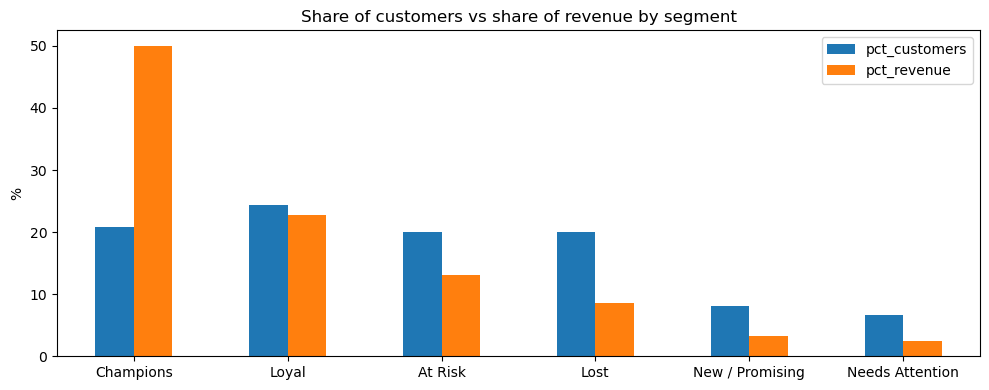

In [36]:
#Chart: share of customers vs share of revenue
ax = summary[["pct_customers", "pct_revenue"]].plot(
        kind="bar", figsize=(10, 4),
        title="Share of customers vs share of revenue by segment")
ax.set_xlabel("")
ax.set_ylabel("%")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [37]:
#WRITING BACK TO POSTGRESQL AND SAVING CSV BACKUP
customer_segments.to_sql("customer_segments", engine, schema="analytics",
                         if_exists="replace", index=False,
                         chunksize=10_000, method="multi")

customer_segments.to_csv("customer_segments.csv", index=False)

pd.read_sql(
    "SELECT segment, COUNT(*) AS customers FROM analytics.customer_segments "
    "GROUP BY segment ORDER BY 2 DESC",
    engine)

,segment,customers
0,Loyal,29797
1,Champions,25551
2,Lost,24441
3,At Risk,24441
4,New / Promising,9886
5,Needs Attention,8088
